In [1]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 34.3 MB/s eta 0:00:00


In [2]:
from Bio import SeqIO

In [3]:
import os
print(os.listdir("/content"))

['.config', 'sequence (2).fasta', 'sample_data']


In [10]:
from Bio import SeqIO
import os

file_name = "/content/sequence (2).fasta"

if not os.path.exists(file_name):
    print("File not found. Please upload the FASTA file.")
else:
    records = list(SeqIO.parse(file_name, "fasta"))

    if not records:
        print("No sequences found. Check your FASTA file.")
    else:
        for record in records:
            print("Sequence ID:", record.id)
            print("Description:", record.description)
            print("DNA/RNA Sequence:", record.seq)
            print("Sequence Length:", len(record.seq))

Sequence ID: NR_076079.2
Description: NR_076079.2 Salmonella enterica subsp. enterica serovar Typhimurium strain LT2 23S ribosomal RNA, complete sequence
DNA/RNA Sequence: TAAGCGACTAAGCGTACACGGTGGATGCCCTGGCAGTCAGAGGCGATGAAGGGCGTGCTAATCTGCGATAAGCGCCGGTAAGGTGATATGAACCGTTATAACCGGCGATACCCGAATGGGGAAACCCAGTGTGACTCGTCACACTATCATTAACTGAATCCATAGGTTAATGAGGCGAACCGGGGGAACTGAAACATCTAAGTACCCCGAGGAAAAGAAATCAACCGAGATTCCCCCAGTAGCGGCGAGCGAACGGGGAGGAGCCCAGAGCCTGAATCAGCATGTGTGTTAGTGGAAGCGTCTGGAAAGGCGCGCGATACAGGGTGACAGCCCCGTACACAAAAGCGCATGTGCTGTGAGCTCGATGAGTAGGGCGGGACACGTGGTATCCTGTCTGAATATGGGGGGACCATCCTCCAAGGCTAAATACTCCTGACTGACCGATAGTGAACCAGTACCGTGAGGGAAAGGCGAAAAGAACCCCGGCGAGGGGAGTGAAAAAGAACCTGAAACCGTGTACGTACAAGCAGTGGGAGCCCCACCACCAAAGCATTCAACACACAAAACAAGCGGTGAATGCTTTGGGGTGGGGTGACTGCGTACCTTTTGTATAATGGGTCAGCGACTTATATTCTGTAGCAAGGTTAACCGAATAGGGGAGCCGGAGGGAAACCGAGTCTTAATTGGGCGTTAAGTTGCAGGGTATAGACCCGAAACCCGGTGATCTAGCCATGGGCAGGTTGAAGGTTGGGTAACACTAACTGGAGGACCGAACCGACTAATGTTGAAAAATTAGCGGATGACCTGTGGCTGGGGGTGAAAGGCCAA

In [11]:
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction

import os

files = [
    f for f in os.listdir("/content")
    if f.lower().endswith((".fasta", ".fa", ".fna"))
]

if files:
    file_name = "/content/" + files[0]

    for record in SeqIO.parse(file_name, "fasta"):
        sequence = str(record.seq).upper()

        print("Sequence ID:", record.id)
        print("Sequence Length:", len(sequence))
        print("A count:", sequence.count("A"))
        print("T count:", sequence.count("T"))
        print("G count:", sequence.count("G"))
        print("C count:", sequence.count("C"))
        print("GC Content (%):", round(gc_fraction(sequence) * 100, 2))
else:
    print("Please upload your FASTA file.")

Sequence ID: NR_076079.2
Sequence Length: 2941
A count: 773
T count: 589
G count: 924
C count: 655
GC Content (%): 53.69


In [12]:
from Bio import SeqIO
import os

files = [
    f for f in os.listdir("/content")
    if f.lower().endswith((".fasta", ".fa", ".fna"))
]

if files:
    file_name = "/content/" + files[0]

    for record in SeqIO.parse(file_name, "fasta"):
        sequence = str(record.seq).upper()

        print("========== SEQUENCE REPORT ==========")
        print("Sequence ID:", record.id)
        print("Description:", record.description)
        print("Total Length:", len(sequence))
        print("A count:", sequence.count("A"))
        print("T count:", sequence.count("T"))
        print("G count:", sequence.count("G"))
        print("C count:", sequence.count("C"))
        print("U count:", sequence.count("U"))

        if "U" in sequence:
            print("Sequence Type: RNA")
        elif "T" in sequence:
            print("Sequence Type: DNA")
        else:
            print("Sequence Type: Check the nucleotide sequence")

        print("=====================================")

else:
    print("No FASTA file found.")

========== SEQUENCE REPORT ==========
Sequence ID: NR_076079.2
Description: NR_076079.2 Salmonella enterica subsp. enterica serovar Typhimurium strain LT2 23S ribosomal RNA, complete sequence
Total Length: 2941
A count: 773
T count: 589
G count: 924
C count: 655
U count: 0
Sequence Type: DNA


In [13]:
from Bio import SeqIO
import os
import pandas as pd

# Find the FASTA file
files = [
    f for f in os.listdir("/content")
    if f.lower().endswith((".fasta", ".fa", ".fna"))
]

if not files:
    print("No FASTA file found. Upload your dataset.")
else:
    file_name = "/content/" + files[0]

    # Read the dataset
    records = list(SeqIO.parse(file_name, "fasta"))

    # Clean and analyse sequences
    results = []

    for record in records:
        sequence = str(record.seq).upper()

        # Remove whitespace
        sequence = "".join(sequence.split())

        # Count nucleotides
        a_count = sequence.count("A")
        t_count = sequence.count("T")
        g_count = sequence.count("G")
        c_count = sequence.count("C")
        u_count = sequence.count("U")

        # Calculate GC content
        gc_content = (
            (g_count + c_count) / len(sequence) * 100
            if len(sequence) > 0 else 0
        )

        results.append({
            "Sequence_ID": record.id,
            "Description": record.description,
            "Sequence_Length": len(sequence),
            "A_Count": a_count,
            "T_Count": t_count,
            "G_Count": g_count,
            "C_Count": c_count,
            "U_Count": u_count,
            "GC_Content_Percent": round(gc_content, 2)
        })

    # Create a summary table
    df = pd.DataFrame(results)

    print("DATA CLEANING AND BASIC ANALYSIS")
    print("================================")
    print("Input file:", files[0])
    print("Total sequences:", len(df))

    if not df.empty:
        print("\nSequence Summary:")
        display(df)

        print("\nBasic Statistics:")
        print(df[["Sequence_Length",
                  "GC_Content_Percent"]].describe())

        # Save the results
        df.to_csv(
            "/content/sequence_analysis_results.csv",
            index=False
        )

        print("\nAnalysis completed.")
        print("Results saved as sequence_analysis_results.csv")

DATA CLEANING AND BASIC ANALYSIS
Input file: sequence (2).fasta
Total sequences: 1

Sequence Summary:


,Sequence_ID,Description,Sequence_Length,A_Count,T_Count,G_Count,C_Count,U_Count,GC_Content_Percent
0,NR_076079.2,NR_076079.2 Salmonella enterica subsp. enteric...,2941,773,589,924,655,0,53.69



Basic Statistics:
       Sequence_Length  GC_Content_Percent
count              1.0                1.00
mean            2941.0               53.69
std                NaN                 NaN
min             2941.0               53.69
25%             2941.0               53.69
50%             2941.0               53.69
75%             2941.0               53.69
max             2941.0               53.69

Analysis completed.
Results saved as sequence_analysis_results.csv


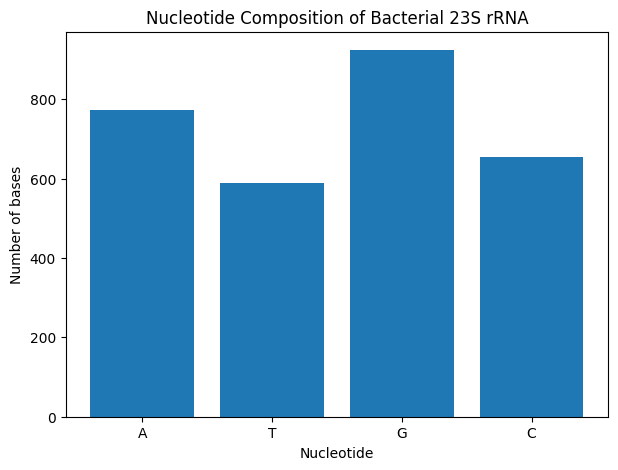

In [14]:
import matplotlib.pyplot as plt
from Bio import SeqIO

# Read your FASTA dataset
file_name = "/content/sequence (2).fasta"

record = next(SeqIO.parse(file_name, "fasta"))
sequence = str(record.seq).upper()

# Count nucleotides
bases = ["A", "T", "G", "C"]
counts = [sequence.count(base) for base in bases]

# Plot graph
plt.figure(figsize=(7, 5))
plt.bar(bases, counts)

plt.xlabel("Nucleotide")
plt.ylabel("Number of bases")
plt.title("Nucleotide Composition of Bacterial 23S rRNA")

plt.savefig("/content/nucleotide_composition.png", dpi=300)
plt.show()

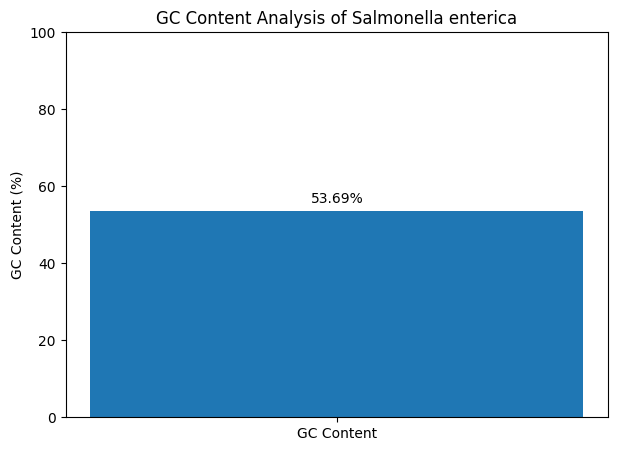

GC Content: 53.69 %
Graph saved as gc_content.png


In [16]:
import matplotlib.pyplot as plt

# Calculate GC content
gc_count = sequence.count("G") + sequence.count("C")
total_length = len(sequence)

gc_content = (gc_count / total_length) * 100

# Create the graph
plt.figure(figsize=(7, 5))

plt.bar(["GC Content"], [gc_content])

plt.ylabel("GC Content (%)")
plt.title("GC Content Analysis of Salmonella enterica")
plt.ylim(0, 100)

# Display percentage
plt.text(0, gc_content + 2, f"{gc_content:.2f}%", ha="center")

# Save the graph
plt.savefig("/content/gc_content.png", dpi=300, bbox_inches="tight")

plt.show()

print("GC Content:", round(gc_content, 2), "%")
print("Graph saved as gc_content.png")